# AI Applications & Mini Project 3 — Process safety and anomaly detection

**Digital Foundation for Chemical Engineers**  \nDuration: 60 minutes

## Today’s goal
Explore a safety-relevant sensor CSV, identify unusual observations using transparent methods, and understand the strict limits of AI in safety-critical work.

## 1. Safety first (10 min)

Anomaly detection finds observations unlike the usual pattern. It can help focus attention, but it is not a safety instrumented function and must not replace alarms, interlocks, operating procedures, hazard studies, or authorised engineering decisions.

An unusual point may reflect a process upset, sensor fault, data-transfer problem, or normal but rare operation. Investigation is needed.

In [13]:
import pandas as pd
import matplotlib.pyplot as plt
#loading the dataset directly from the raw github URL
data_url = 'https://raw.githubusercontent.com/Khushi-chan/Module_5_6_Both/refs/heads/main/05_03_process_safety_anomaly_detection.ipynb'
safety_data = pd.read_csv('data/safety_sensor_120.csv')
safety_data['timestamp'] = pd.to_datetime(safety_data['timestamp'])
safety_data.head()

,timestamp,reactor,temperature_c,pressure_bar,flow_m3_h,relief_valve_state
0,2026-02-02 08:00:00,R1,78.0,4.70,12.00,CLOSED
1,2026-02-02 09:00:00,R2,78.5,4.75,12.12,CLOSED
2,2026-02-02 10:00:00,R1,79.1,4.80,12.24,CLOSED
3,2026-02-02 11:00:00,R2,79.7,4.85,12.36,CLOSED
4,2026-02-02 12:00:00,R1,80.2,4.90,12.48,CLOSED


## 2. Trend and range check (12 min)
Inspect what normally occurs before defining unusual. Descriptive statistics and time trends make assumptions visible.

,temperature_c,pressure_bar,flow_m3_h
count,120.000000,120.000000,120.000000
mean,81.455833,4.943750,12.420000
std,2.454452,0.203082,0.276107
min,78.000000,4.700000,12.000000
25%,79.700000,4.800000,12.210000
50%,81.300000,4.925000,12.420000
75%,83.000000,5.050000,12.630000
max,93.000000,5.900000,12.840000


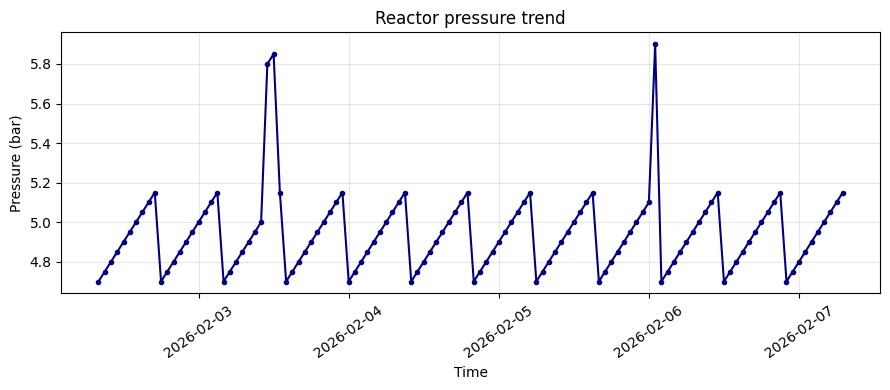

In [14]:
display(safety_data[['temperature_c', 'pressure_bar', 'flow_m3_h']].describe())
plt.figure(figsize=(9, 4))
plt.plot(safety_data['timestamp'], safety_data['pressure_bar'], marker='.', color='navy')
plt.title('Reactor pressure trend')
plt.xlabel('Time')
plt.ylabel('Pressure (bar)')
plt.grid(alpha=0.3)
plt.xticks(rotation=35)
plt.tight_layout()
plt.show()

,temperature_c,pressure_bar,flow_m3_h
count,120.000000,120.000000,120.000000
mean,81.455833,4.943750,12.420000
std,2.454452,0.203082,0.276107
min,78.000000,4.700000,12.000000
25%,79.700000,4.800000,12.210000
50%,81.300000,4.925000,12.420000
75%,83.000000,5.050000,12.630000
max,93.000000,5.900000,12.840000


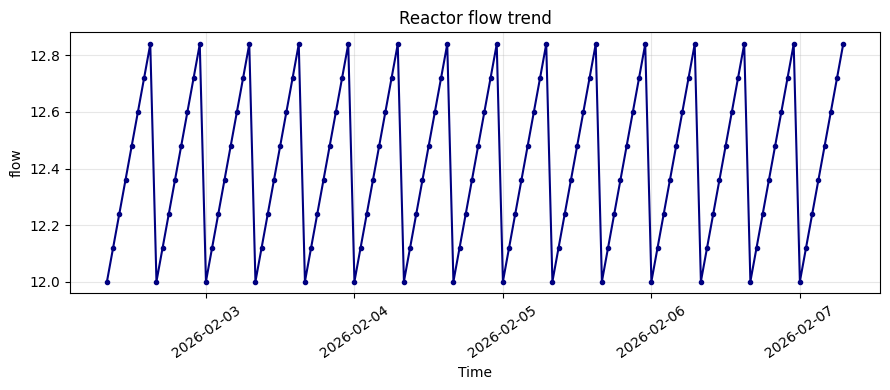

In [15]:
display(safety_data[['temperature_c', 'pressure_bar', 'flow_m3_h']].describe())
plt.figure(figsize=(9, 4))
plt.plot(safety_data['timestamp'], safety_data['flow_m3_h'], marker='.', color='navy')
plt.title('Reactor flow trend')
plt.xlabel('Time')
plt.ylabel('flow')
plt.grid(alpha=0.3)
plt.xticks(rotation=35)
plt.tight_layout()
plt.show()

,temperature_c,pressure_bar,flow_m3_h
count,120.000000,120.000000,120.000000
mean,81.455833,4.943750,12.420000
std,2.454452,0.203082,0.276107
min,78.000000,4.700000,12.000000
25%,79.700000,4.800000,12.210000
50%,81.300000,4.925000,12.420000
75%,83.000000,5.050000,12.630000
max,93.000000,5.900000,12.840000


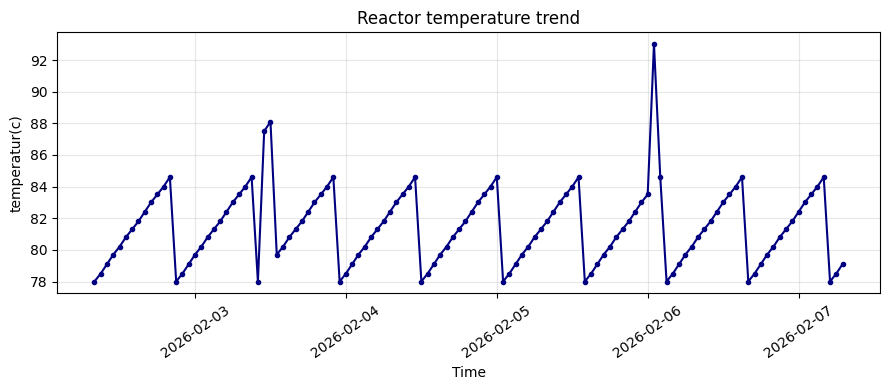

In [16]:
display(safety_data[['temperature_c', 'pressure_bar', 'flow_m3_h']].describe())
plt.figure(figsize=(9, 4))
plt.plot(safety_data['timestamp'], safety_data['temperature_c'], marker='.', color='navy')
plt.title('Reactor temperature trend')
plt.xlabel('Time')
plt.ylabel('temperatur(c)')
plt.grid(alpha=0.3)
plt.xticks(rotation=35)
plt.tight_layout()
plt.show()

## 3. Simple statistical anomaly score (15 min)
A z-score measures distance from the observed mean in standard-deviation units. It is a classroom screening method; it is sensitive to outliers. We flag points with absolute z-score above 2.5 for review.

In [17]:
pressure_mean = safety_data['pressure_bar'].mean()
pressure_std = safety_data['pressure_bar'].std()
safety_data['pressure_z_score'] = (safety_data['pressure_bar'] - pressure_mean) / pressure_std
anomalies = safety_data[safety_data['pressure_z_score'].abs() > 2.5]
display(anomalies[['timestamp', 'reactor', 'pressure_bar', 'pressure_z_score']])

,timestamp,reactor,pressure_bar,pressure_z_score
27,2026-02-03 11:00:00,R2,5.80,4.216286
28,2026-02-03 12:00:00,R1,5.85,4.462493
89,2026-02-06 01:00:00,R2,5.90,4.708699


In [19]:
temperature_mean = safety_data['temperature_c'].mean()
temperature_std = safety_data['temperature_c'].std()
safety_data['temperature_z_score'] = (safety_data['temperature_c'] - temperature_mean) / temperature_std
anomalies = safety_data[safety_data['temperature_z_score'].abs() > 2.5]
display(anomalies[['timestamp', 'reactor', 'temperature_c', 'temperature_z_score']])

,timestamp,reactor,temperature_c,temperature_z_score
28,2026-02-03 12:00:00,R1,88.1,2.706986
89,2026-02-06 01:00:00,R2,93.0,4.703358


**Try it (4 min):** Repeat the z-score approach for temperature. Do the same rows appear?

**Challenge:** Define an anomaly when either pressure or temperature z-score exceeds 2.5, then count flags by reactor.

## Case discussion (9 min)
An anomaly tool flags a high pressure point, but the operator display shows stable pressure. List two possible data explanations and two process explanations. What information would you check before acting?

**Challenge:** Write a short escalation message that reports the observation without claiming root cause.

## Exit check
You can explain anomaly detection, calculate a simple outlier screen, and state why it cannot replace process-safety safeguards.